# 1D Diffusion Equation: Explicit FTCS Scheme

**References:** `Notes/lec_pde.pdf`, `Notes/Tutorial_03_11_26.pptx`, `Notes/1D_diffusion.ipynb` (Professor code), `Notes/Quiz2/01_1D_Diffusion_FTCS.ipynb`

## Concept, Formulas & Stability
The 1D diffusion equation is:
$$\frac{\partial \rho}{\partial t} = D \frac{\partial^2 \rho}{\partial x^2}$$

- **FTCS Discretization (Forward Time, Centered Space):**
  $$\rho_i^{n+1} = \rho_i^n + C (\rho_{i+1}^n + \rho_{i-1}^n - 2\rho_i^n), \qquad C = \frac{D \Delta t}{\Delta x^2}$$
- **Stability Condition (von Neumann):**
  $$C = \frac{D \Delta t}{\Delta x^2} \le \frac{1}{2} \implies \Delta t \le \frac{\Delta x^2}{2D}$$
- **Boundary Conditions:**
  - **Dirichlet (Fixed value):** $\rho_0 = a,\; \rho_{N-1} = b$ (breaks conservation; steady state is a straight line).
  - **Neumann (No-flux):** $\frac{\partial \rho}{\partial x} = 0$ at ends $\implies \rho_0 = \rho_1,\; \rho_{N-1} = \rho_{N-2}$ (conserves total particles).
  - **Periodic:** wraps around from $x = L$ back to $x = 0$.
- **Fourier Mode Decay:** $\rho(x, t) \sim e^{-D k^2 t}$ with decay time $\tau_k = \frac{1}{D k^2} = \frac{\lambda^2}{4\pi^2 D}$ (short wavelengths fade much faster).
- **Limitations:** If $C > 0.5$, explicit FTCS becomes unstable and blows up with wild oscillations.

Diffusion Courant number C = 0.2222 (Must be <= 0.5 for stability)


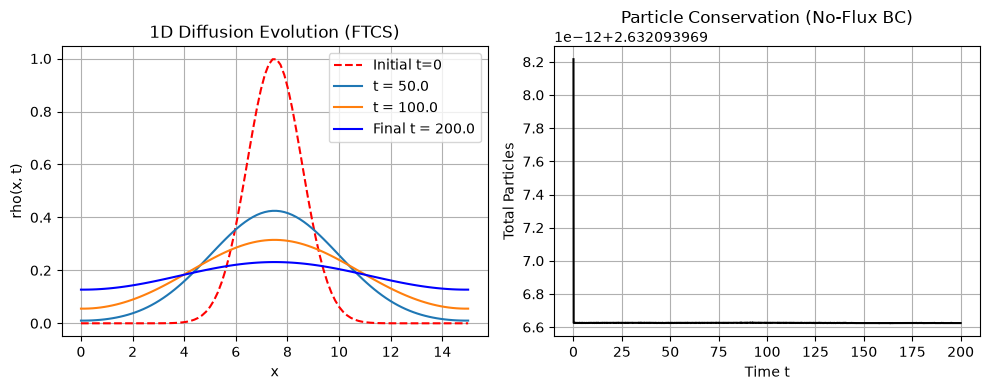

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters (Quiz 2 Reference Code)
N = 100               # Number of grid points
dx = 0.15             # Spatial resolution
L = N * dx            # System size
D = 0.05              # Diffusion coefficient
dt = 0.1              # Temporal step (D*dt/dx^2 = 0.222 <= 0.5)
t_end = 200.0         # Final simulation time

C = D * dt / (dx**2)
print(f"Diffusion Courant number C = {C:.4f} (Must be <= 0.5 for stability)")
assert C <= 0.5, "Stability condition violated!"

x = np.linspace(0, L, N)
t = np.arange(0, t_end + dt, dt)

# Initial condition: Gaussian pulse at center
rho_0 = np.exp(-((x - L/2) / 1.5)**2)
rho = rho_0.copy()
rho_temp = np.zeros(N)

rho_history = [rho.copy()]
total_particles = [np.sum(rho[1:-1]) * dx]

for n in range(1, len(t)):
    for i in range(1, N - 1):
        rho_temp[i] = rho[i] + C * (rho[i+1] + rho[i-1] - 2 * rho[i])

    # Neumann (No-Flux) boundary conditions
    rho_temp[0] = rho_temp[1]
    rho_temp[-1] = rho_temp[-2]

    rho = rho_temp.copy()
    rho_history.append(rho.copy())
    total_particles.append(np.sum(rho[1:-1]) * dx)

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(x, rho_0, 'r--', label='Initial t=0')
plt.plot(x, rho_history[len(t)//4], label=f't = {t[len(t)//4]:.1f}')
plt.plot(x, rho_history[len(t)//2], label=f't = {t[len(t)//2]:.1f}')
plt.plot(x, rho, 'b-', label=f'Final t = {t_end:.1f}')
plt.xlabel('x'); plt.ylabel('rho(x, t)')
plt.title('1D Diffusion Evolution (FTCS)')
plt.legend(); plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(t, total_particles, 'k-')
plt.xlabel('Time t'); plt.ylabel('Total Particles')
plt.title('Particle Conservation (No-Flux BC)')
plt.grid(True)
plt.tight_layout()
plt.show()

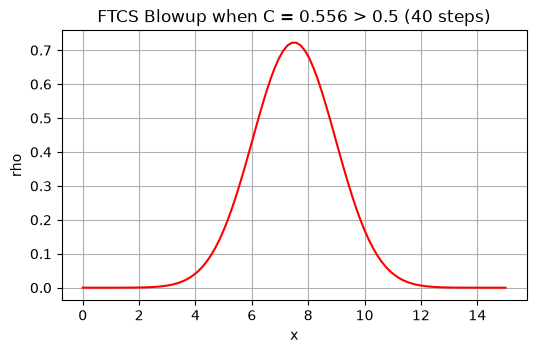

In [2]:
# Instability check: what happens if C > 0.5
dt_bad = 0.25
C_bad = D * dt_bad / (dx**2)   # C_bad = 0.556 > 0.5
rho_bad = np.exp(-((x - L/2) / 1.5)**2)
rho_next = np.zeros(N)

for step in range(40):
    for i in range(1, N - 1):
        rho_next[i] = rho_bad[i] + C_bad * (rho_bad[i+1] + rho_bad[i-1] - 2 * rho_bad[i])
    rho_next[0] = rho_next[1]
    rho_next[-1] = rho_next[-2]
    rho_bad = rho_next.copy()

plt.figure(figsize=(6, 3.5))
plt.plot(x, rho_bad, 'r-')
plt.title(f'FTCS Blowup when C = {C_bad:.3f} > 0.5 (40 steps)')
plt.xlabel('x'); plt.ylabel('rho')
plt.grid(True)
plt.show()

---
## Professor's In-Class Code (`Notes/1D_diffusion.ipynb`)
Exact code from the professor's notebook with Dirichlet boundary conditions (`rho[0] = 1, rho[-1] = 0`).

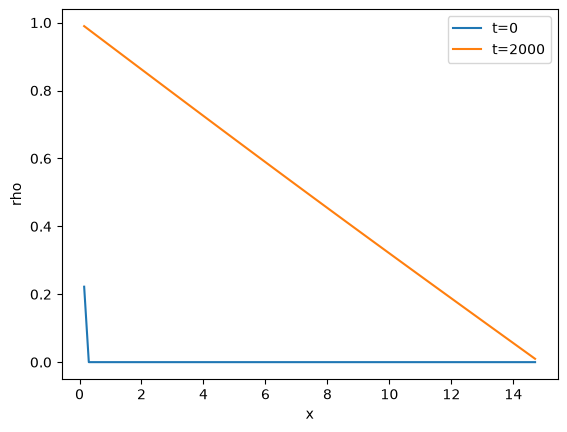

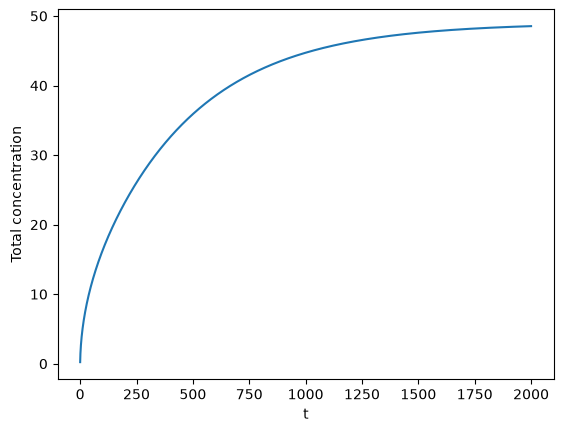

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
N = 100          # Total number of grid points
dt = 0.1         # Temporal step size
dx = 0.15        # Spatial step size
D = 0.05         # Diffusion constant
L = N * dx       # System size
t_end = 2000      # Final time

# Initialize arrays
rho = np.zeros(N)       # Concentration field 
rho_0 = np.zeros(N)     # Initial concentration field
rho_temp = np.zeros(N)  # temporary concentration-field vector 

# Spatial and temporal vectors
x = np.arange(0, L, dx) # site vector
t = np.arange(dt, t_end, dt) # time vector

# Initial condition
#rho_0 = np.exp(-((x - L/2)/5)**2)

# Initialize concentration field
rho = rho_0.copy()

rho_T = np.zeros((N, len(t))) # Array to store concentration at different time points
n = np.zeros(len(t)) # Total no. of particles

for i in range(len(t)):

    '''
    # No-flux(Neumann) boundary conditions
    rho[-1] = rho[-2]
    rho[0] = rho[1]
    '''
    
    # Dirichlet boundary conditions
    rho[0]=1
    rho[-1]=0
    

    # Update concentration at interior grid points
    for p in range(1, N-1):

        rho_temp[p] =(rho[p] + D * dt /(dx * dx) *(rho[p+1] + rho[p-1] - 2*rho[p]))
        
    # Update concentration field
    rho = rho_temp.copy() # use .copy() to create separate memory space for rho and rho_temp
    #rho[1:N-2]=rho_temp[1:N-2]

    # Store concentration profile
    rho_T[:, i] = rho

    # Total concentration
    n[i] = np.sum(rho[1:-1])

plt.plot(x[1:-1], rho_T[1:-1, 0], label='t=0')
plt.plot(x[1:-1], rho_T[1:-1, len(t)-1], label=f't={t_end}')
plt.xlabel('x'); plt.ylabel('rho'); plt.legend()

plt.figure()
plt.plot(t,n)
plt.xlabel('t'); plt.ylabel('Total concentration')
plt.show()